# UCMF — Predição da condição cardíaca (Normal × Anormal)
**Mineração de Dados — INF/UFG — Grupo 6**
João Guilherme da Silva Chaveiro · Luiany Gonçalves Carvalho · Nayane Januário Santos · Victor Pereira Sousa Pires

Notebook reprodutível do relatório A2. O código está em `ucmf_pipeline.py`; aqui executamos cada etapa do KDD.
`RANDOM_STATE = 42` em todas as etapas aleatórias (divisão, validação cruzada, modelos, imputação, bootstrap e permutação).

**Data leakage:** o atributo `SOPRO` é excluído de todos os modelos e usado apenas no experimento de controle.

In [1]:
# No Google Colab: descomente para clonar o repositório
# !git clone https://github.com/Nayanejs/ucmf-kdd-grupo6.git
# %cd ucmf-kdd-grupo6
!pip install -q -r requirements.txt

In [2]:
import json, numpy as np, pandas as pd
import ucmf_pipeline as up
up.DATA, up.OUT = 'data/UCMF_raw.csv', 'results'
print('RANDOM_STATE =', up.RANDOM_STATE)

RANDOM_STATE = 42


## 1. Seleção e limpeza determinística (regras fixas, linha a linha)

In [3]:
raw = pd.read_csv(up.DATA, dtype=str)
print('Base bruta:', raw.shape)
df, log = up.clean(raw)
print(log)
print('Proporção de anormais: %.3f' % df['y'].mean())
df[up.NUM].describe().T.round(2)

Base bruta: (12873, 21)


{'bruto': 12873, 'sem_rotulo': 1168, 'duplicatas': 235, 'acima_19': 76, 'final': 11394}
Proporção de anormais: 0.427


,count,mean,std,min,25%,50%,75%,max
IDADE,10711.0,5.17,4.65,0.00,1.00,3.93,8.47,19.84
LOG_PESO,9440.0,2.80,0.76,0.26,2.30,2.83,3.35,5.06
ALTURA,7939.0,100.26,34.90,31.00,70.00,99.00,128.00,198.00
LOG_IMC,7557.0,2.89,0.18,2.11,2.78,2.87,2.99,4.04
PAS,5027.0,101.30,11.41,60.00,90.00,100.00,110.00,180.00
PAD,5018.0,62.51,8.95,23.00,60.00,60.00,70.00,120.00
FC,10692.0,95.30,18.05,43.00,80.00,92.00,100.00,250.00


## 2. Vazamento de dados: SOPRO × alvo (proporção por linha)

In [4]:
pd.crosstab(df['SOPRO'].fillna('NA'), df['y'], margins=True, normalize='index').round(3)

y,0,1
SOPRO,,
Ausente,0.899,0.101
NA,0.818,0.182
Outro,0.176,0.824
Sistolico,0.042,0.958
All,0.573,0.427


## 3. Pré-processamento ajustado só no treino + modelagem
Divisão 80/20 estratificada, GridSearchCV com 5 folds estratificados (AUC-ROC), avaliação única no teste,
experimento de vazamento, análise de erros e importância por permutação (cerca de 7 minutos).

In [5]:
up.main()

Dummy (classe majoritaria) {'strategy': 'most_frequent'} 0.5 {'Acuracia': 0.573, 'Acur_bal': 0.5, 'Precisao': 0.0, 'Sensib': 0.0, 'Especif': np.float64(1.0), 'F1': 0.0, 'ROC_AUC': 0.5, 'PR_AUC': 0.427, 'TN': 1306, 'FP': 0, 'FN': 973, 'TP': 0}


Regressao Logistica {'C': 1, 'class_weight': 'balanced'} 0.7846 {'Acuracia': 0.751, 'Acur_bal': 0.74, 'Precisao': 0.731, 'Sensib': 0.66, 'Especif': np.float64(0.819), 'F1': 0.694, 'ROC_AUC': 0.798, 'PR_AUC': 0.777, 'TN': 1070, 'FP': 236, 'FN': 331, 'TP': 642}


Random Forest {'class_weight': None, 'max_depth': 10, 'max_features': 0.3, 'min_samples_leaf': 1} 0.7961 {'Acuracia': 0.753, 'Acur_bal': 0.732, 'Precisao': 0.783, 'Sensib': 0.585, 'Especif': np.float64(0.879), 'F1': 0.669, 'ROC_AUC': 0.809, 'PR_AUC': 0.786, 'TN': 1148, 'FP': 158, 'FN': 404, 'TP': 569}


XGBoost {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 200, 'scale_pos_weight': 1.3407806882383153} 0.8005 {'Acuracia': 0.756, 'Acur_bal': 0.745, 'Precisao': 0.737, 'Sensib': 0.667, 'Especif': np.float64(0.822), 'F1': 0.7, 'ROC_AUC': 0.811, 'PR_AUC': 0.787, 'TN': 1074, 'FP': 232, 'FN': 324, 'TP': 649}


{
 "limpeza": {
  "bruto": 12873,
  "sem_rotulo": 1168,
  "duplicatas": 235,
  "acima_19": 76,
  "final": 11394
 },
 "melhor": "XGBoost",
 "limiar_sens90": 0.2861301600933075,
 "teste_limiar_sens90": {
  "Acuracia": 0.6195699868363317,
  "Acur_bal": 0.6549678218484062,
  "Precisao": 0.5323170731707317,
  "Sensib": 0.8972250770811921,
  "Especif": 0.4127105666156202,
  "F1": 0.6681974741676234,
  "ROC_AUC": 0.8107580004690189,
  "PR_AUC": 0.7871580035028493,
  "TN": 539,
  "FP": 767,
  "FN": 100,
  "TP": 873
 },
 "com_sopro": {
  "Acuracia": 0.9271610355419043,
  "Acur_bal": 0.9201999153247955,
  "Precisao": 0.9528619528619529,
  "Sensib": 0.8725590955806783,
  "Especif": 0.9678407350689127,
  "F1": 0.9109442060085837,
  "ROC_AUC": 0.9560161103232925,
  "PR_AUC": 0.9585368126761538,
  "TN": 1264,
  "FP": 42,
  "FN": 124,
  "TP": 849
 },
 "regra_so_sopro": {
  "Acuracia": 0.9218955682316805,
  "Acur_bal": 0.9132472626143233,
  "Precisao": 0.9584775086505191,
  "Sensib": 0.854059609455292

## 4. Resultados

In [6]:
r = json.load(open('results/results.json'))
pd.DataFrame({k: {'AUC CV': '%.3f ± %.3f' % tuple(m['cv_auc']), **{a: round(b, 3) for a, b in m['teste'].items()}}
              for k, m in r['modelos'].items()}).T

,AUC CV,Acuracia,Acur_bal,Precisao,Sensib,Especif,F1,ROC_AUC,PR_AUC,TN,FP,FN,TP
Dummy (classe majoritaria),0.500 ± 0.000,0.573,0.5,0.0,0.0,1.0,0.0,0.5,0.427,1306,0,973,0
Regressao Logistica,0.785 ± 0.010,0.751,0.74,0.731,0.66,0.819,0.694,0.798,0.777,1070,236,331,642
Random Forest,0.796 ± 0.012,0.753,0.732,0.783,0.585,0.879,0.669,0.809,0.786,1148,158,404,569
XGBoost,0.800 ± 0.012,0.756,0.745,0.737,0.667,0.822,0.7,0.811,0.787,1074,232,324,649


In [7]:
print('IC95% AUC (bootstrap):', {k: [round(x, 3) for x in v] for k, v in r['auc_ic95'].items()})
print('Diferença AUC XGB - RL [média, IC95%]:', [round(x, 4) for x in r['dif_auc_xgb_rl']])
print('Com SOPRO (vazamento):', {k: round(v, 3) for k, v in r['com_sopro'].items()})
print('Regra só SOPRO:', {k: round(v, 3) for k, v in r['regra_so_sopro'].items()})
print('Limiar sens>=0,90 (OOF treino): %.3f' % r['limiar_sens90'])
print({k: round(v, 3) for k, v in r['teste_limiar_sens90'].items()})

IC95% AUC (bootstrap): {'Dummy (classe majoritaria)': [0.5, 0.5], 'Regressao Logistica': [0.779, 0.818], 'Random Forest': [0.791, 0.827], 'XGBoost': [0.793, 0.829]}
Diferença AUC XGB - RL [média, IC95%]: [0.0125, 0.0039, 0.0218]
Com SOPRO (vazamento): {'Acuracia': 0.927, 'Acur_bal': 0.92, 'Precisao': 0.953, 'Sensib': 0.873, 'Especif': 0.968, 'F1': 0.911, 'ROC_AUC': 0.956, 'PR_AUC': 0.959, 'TN': 1264, 'FP': 42, 'FN': 124, 'TP': 849}
Regra só SOPRO: {'Acuracia': 0.922, 'Acur_bal': 0.913, 'Precisao': 0.958, 'Sensib': 0.854, 'Especif': 0.972, 'F1': 0.903, 'ROC_AUC': 0.913, 'PR_AUC': 0.881, 'TN': 1270, 'FP': 36, 'FN': 142, 'TP': 831}
Limiar sens>=0,90 (OOF treino): 0.286
{'Acuracia': 0.62, 'Acur_bal': 0.655, 'Precisao': 0.532, 'Sensib': 0.897, 'Especif': 0.413, 'F1': 0.668, 'ROC_AUC': 0.811, 'PR_AUC': 0.787, 'TN': 539, 'FP': 767, 'FN': 100, 'TP': 873}


In [8]:
pd.DataFrame(r['erros']).T.round(3)

,n,idade_mediana,pct_sopro_presente,pct_motivo2_sopro,pct_b2_alterada,pct_motivo1_parecer,pct_cardiopatia_estab
FN,324.0,4.92,0.759,0.028,0.000,0.608,0.022
FP,232.0,1.47,0.043,0.293,0.034,0.151,0.203
VP,649.0,1.28,0.901,0.522,0.191,0.094,0.240
VN,1074.0,5.70,0.024,0.025,0.000,0.674,0.008


In [9]:
pd.DataFrame(r['importancia'], index=['queda_AUC', 'desvio']).T.round(4).head(12)

,queda_AUC,desvio
MOTIVO2,0.0823,0.0067
B2,0.0439,0.0034
MOTIVO1,0.0269,0.0030
FC,0.0257,0.0041
HDA_INFORMADO,0.0108,0.0027
IDADE,0.0075,0.0017
Convenio,0.0042,0.0011
LOG_PESO,0.0028,0.0025
HDA_ASSINTOMATICO,0.0027,0.0012
SEXO,0.0018,0.0006


## 5. Figuras do relatório

ok


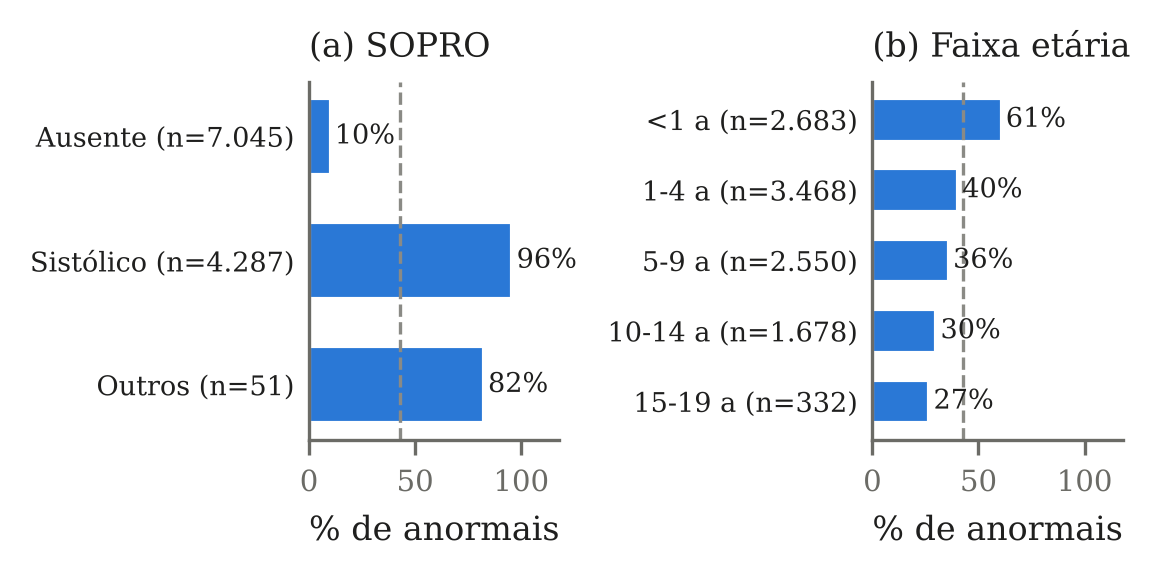

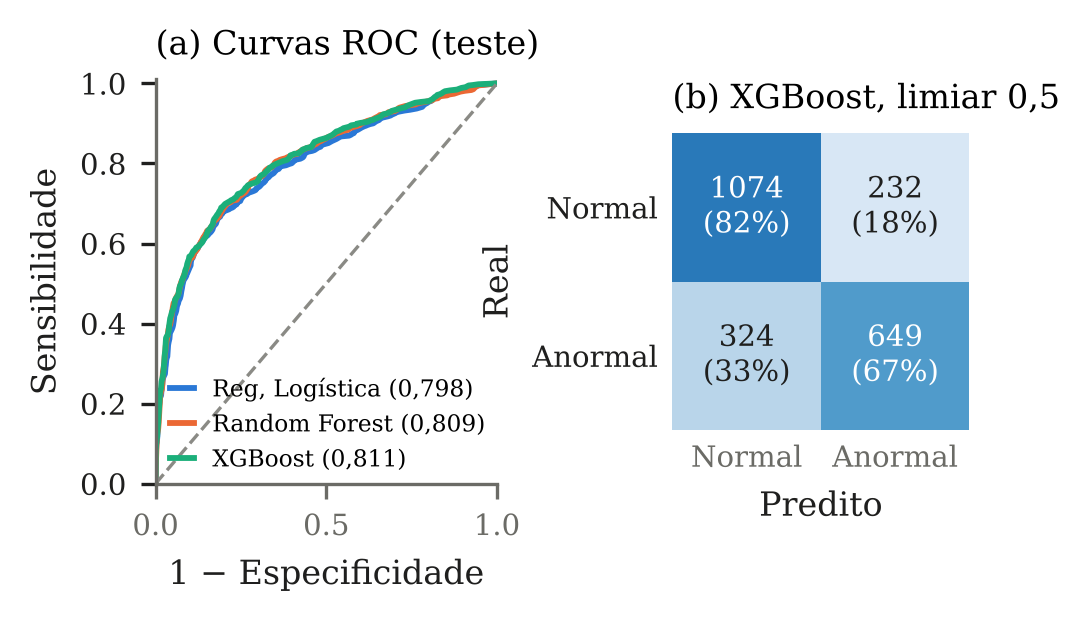

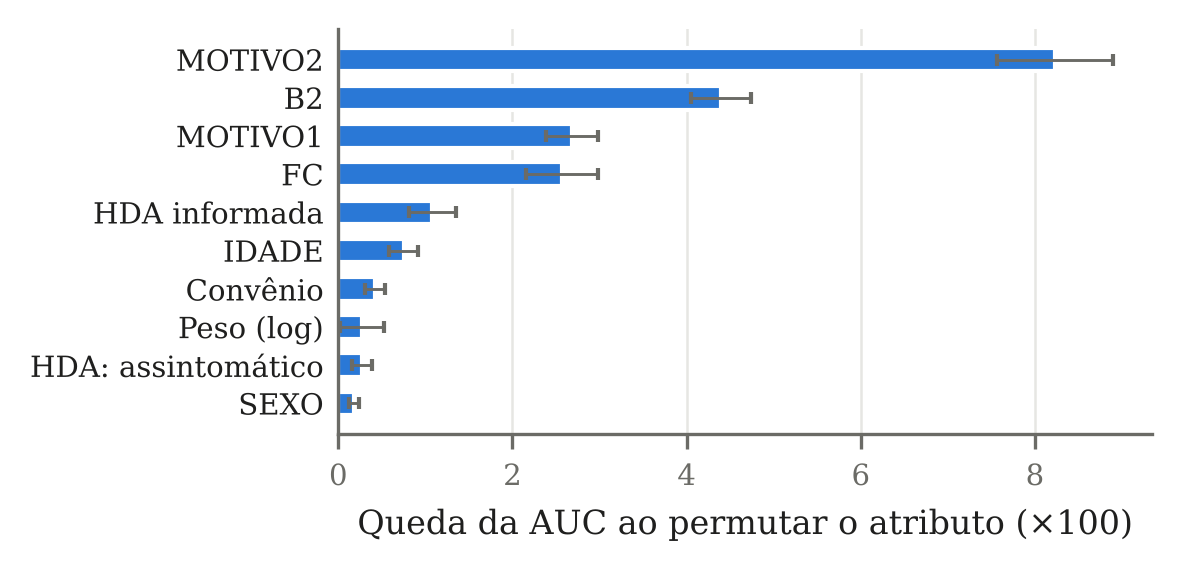

In [10]:
!python make_figures.py results paper
from IPython.display import Image, display
for f in ['fig_eda', 'fig_roc_cm', 'fig_imp']:
    display(Image(f'paper/{f}.png'))